# Prediksi Gagal Bayar Pinjaman (Credit Risk) dengan Regresi Logistik

**Studi Kasus:** Sebagai Data Scientist di lembaga keuangan, kita membangun model yang memprediksi apakah seorang nasabah **akan gagal bayar (default)** berdasarkan data demografis, kondisi keuangan, dan riwayat kreditnya. Hasilnya akan diintegrasikan ke aplikasi web (Flask) agar analis kredit mendapat prediksi instan beserta skor probabilitasnya.

**Alur notebook:**
1. Import library dan load dataset
2. Eksplorasi Data (EDA)
3. Pembersihan data dan pra-pemrosesan
4. Split data, imputasi, scaling, dan SMOTE
5. Pelatihan model Regresi Logistik
6. Evaluasi (Confusion Matrix, Precision, Recall, F1, AUC)
7. Penyimpanan model dan scaler dengan Joblib ke folder `model/`
8. Uji coba prediksi satu nasabah (simulasi untuk Flask)

## 1. Import Library

In [1]:
# Import library yang dibutuhkan
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, roc_auc_score, precision_score, recall_score,
                             f1_score, accuracy_score)

# SMOTE (jika belum terpasang: pip install imbalanced-learn)
from imblearn.over_sampling import SMOTE

import warnings
warnings.filterwarnings('ignore')
sns.set_style('whitegrid')

## 2. Load Dataset

In [2]:
df = pd.read_csv('../data/credit_risk.csv')

# Mengganti nama 2 kolom agar tidak membingungkan:
#   'Status'  = target (1 = gagal bayar, 0 = lancar)
#   'Default' = fitur riwayat (pernah gagal bayar sebelumnya: Y/N)
df = df.rename(columns={'Status': 'Loan_Status', 'Default': 'Prev_Default'})

print("Ukuran data (baris, kolom):", df.shape)
df.head()

Ukuran data (baris, kolom): (32581, 12)


,Id,Age,Income,Home,Emp_length,Intent,Amount,Rate,Loan_Status,Percent_income,Prev_Default,Cred_length
0,0,22,59000,RENT,123.0,PERSONAL,35000,16.02,1,0.59,Y,3
1,1,21,9600,OWN,5.0,EDUCATION,1000,11.14,0,0.10,N,2
2,2,25,9600,MORTGAGE,1.0,MEDICAL,5500,12.87,1,0.57,N,3
3,3,23,65500,RENT,4.0,MEDICAL,35000,15.23,1,0.53,N,2
4,4,24,54400,RENT,8.0,MEDICAL,35000,14.27,1,0.55,Y,4


**Deskripsi kolom:**

| Kolom | Keterangan |
|---|---|
| `Id` | ID baris (tidak dipakai sebagai fitur) |
| `Age` | Usia nasabah |
| `Income` | Pendapatan tahunan |
| `Home` | Status tempat tinggal (RENT / OWN / MORTGAGE / OTHER) |
| `Emp_length` | Lama bekerja (tahun) |
| `Intent` | Tujuan pinjaman |
| `Amount` | Jumlah pinjaman |
| `Rate` | Suku bunga pinjaman (%) |
| `Percent_income` | Rasio jumlah pinjaman terhadap pendapatan |
| `Prev_Default` | Pernah gagal bayar sebelumnya (Y/N) |
| `Cred_length` | Lama riwayat kredit (tahun) |
| `Loan_Status` | **Target**: 1 = gagal bayar, 0 = tidak |

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Id              32581 non-null  int64  
 1   Age             32581 non-null  int64  
 2   Income          32581 non-null  int64  
 3   Home            32581 non-null  object 
 4   Emp_length      31686 non-null  float64
 5   Intent          32581 non-null  object 
 6   Amount          32581 non-null  int64  
 7   Rate            29465 non-null  float64
 8   Loan_Status     32581 non-null  int64  
 9   Percent_income  32581 non-null  float64
 10  Prev_Default    32581 non-null  object 
 11  Cred_length     32581 non-null  int64  
dtypes: float64(3), int64(6), object(3)
memory usage: 3.0+ MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Id,32581.0,16290.006139,9405.479594,0.00,8145.00,16290.00,24435.00,32780.00
Age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
Income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
Emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
Amount,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
Rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
Loan_Status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
Percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
Cred_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00


## 3. Eksplorasi Data (EDA)

### 3.1 Distribusi Variabel Target (Cek Ketidakseimbangan Kelas)

Loan_Status
0    25473
1     7108
Name: count, dtype: int64

Persentase:
Loan_Status
0    78.18
1    21.82
Name: proportion, dtype: float64


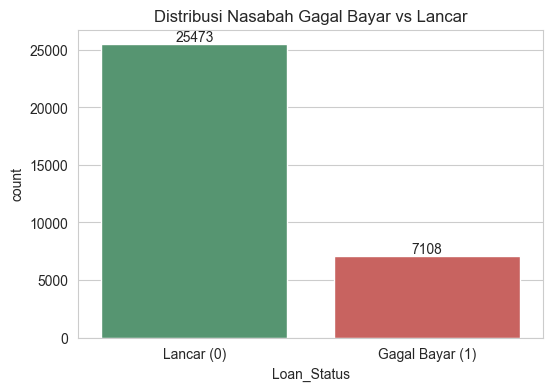

In [5]:
print(df['Loan_Status'].value_counts())
print("\nPersentase:")
print((df['Loan_Status'].value_counts(normalize=True) * 100).round(2))

fig, ax = plt.subplots(figsize=(6, 4))
sns.countplot(x='Loan_Status', data=df, palette=['#4C9F70', '#D9534F'], ax=ax)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha='center', va='bottom')
ax.set_xticklabels(['Lancar (0)', 'Gagal Bayar (1)'])
plt.title('Distribusi Nasabah Gagal Bayar vs Lancar')
plt.show()

**Insight:** Nasabah gagal bayar hanya sekitar 22%, jauh lebih sedikit dari nasabah lancar (~78%). Data **tidak seimbang**, sehingga akan diterapkan **SMOTE** pada data latih.

### 3.2 Missing Value dan Outlier

In [6]:
missing = df.isnull().sum()
missing = missing[missing > 0]
print("Kolom dengan missing value:")
print(missing)
print("\nPersentase:")
print((missing / len(df) * 100).round(2))
print("\nJumlah baris duplikat (tanpa kolom Id):", df.drop(columns='Id').duplicated().sum())

Kolom dengan missing value:
Emp_length     895
Rate          3116
dtype: int64

Persentase:
Emp_length    2.75
Rate          9.56
dtype: float64

Jumlah baris duplikat (tanpa kolom Id): 165


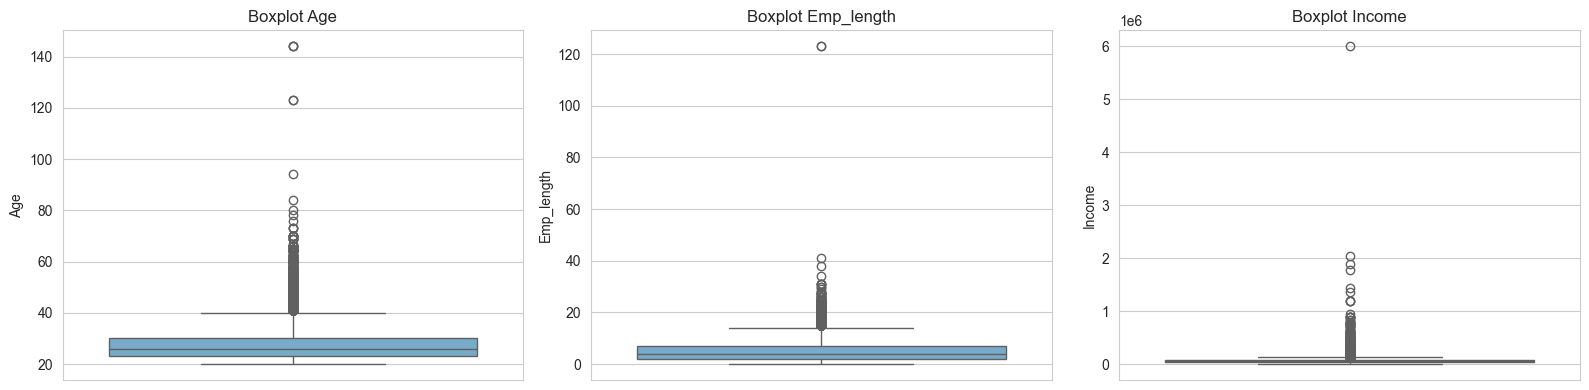

Usia maksimum       : 144 tahun
Lama kerja maksimum : 123.0 tahun
Baris dengan Age > 100         : 5
Baris dengan Emp_length > 60   : 2


In [7]:
# Boxplot untuk mendeteksi nilai tidak wajar (outlier)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ['Age', 'Emp_length', 'Income']):
    sns.boxplot(y=df[col], ax=ax, color='#6BAED6')
    ax.set_title(f'Boxplot {col}')
plt.tight_layout()
plt.show()

print("Usia maksimum       :", df['Age'].max(), "tahun")
print("Lama kerja maksimum :", df['Emp_length'].max(), "tahun")
print("Baris dengan Age > 100         :", (df['Age'] > 100).sum())
print("Baris dengan Emp_length > 60   :", (df['Emp_length'] > 60).sum())

**Temuan:** Ada nilai yang tidak masuk akal (usia 144 tahun, lama bekerja 123 tahun) serta missing value pada `Emp_length` dan `Rate`. Ini akan dibersihkan pada tahap pra-pemrosesan.

### 3.3 Fitur Kategorikal terhadap Target

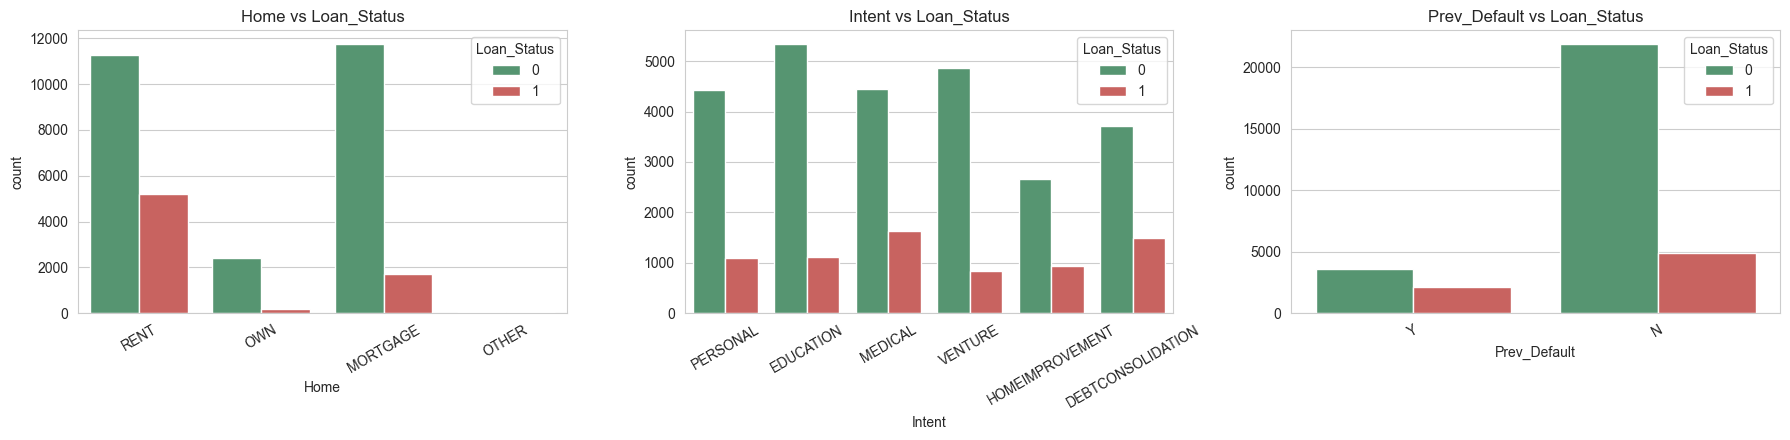

In [8]:
cat_cols_eda = ['Home', 'Intent', 'Prev_Default']
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, col in zip(axes, cat_cols_eda):
    sns.countplot(x=col, hue='Loan_Status', data=df, palette=['#4C9F70', '#D9534F'], ax=ax)
    ax.set_title(f'{col} vs Loan_Status')
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [9]:
# Persentase gagal bayar per kategori
for col in cat_cols_eda:
    rate = (df.groupby(col)['Loan_Status'].mean() * 100).round(2).sort_values(ascending=False)
    print(f"Persentase gagal bayar berdasarkan {col}:\n{rate}\n")

Persentase gagal bayar berdasarkan Home:
Home
RENT        31.57
OTHER       30.84
MORTGAGE    12.57
OWN          7.47
Name: Loan_Status, dtype: float64

Persentase gagal bayar berdasarkan Intent:
Intent
DEBTCONSOLIDATION    28.59
MEDICAL              26.70
HOMEIMPROVEMENT      26.10
PERSONAL             19.89
EDUCATION            17.22
VENTURE              14.81
Name: Loan_Status, dtype: float64

Persentase gagal bayar berdasarkan Prev_Default:
Prev_Default
Y    37.81
N    18.39
Name: Loan_Status, dtype: float64



### 3.4 Fitur Numerik terhadap Target

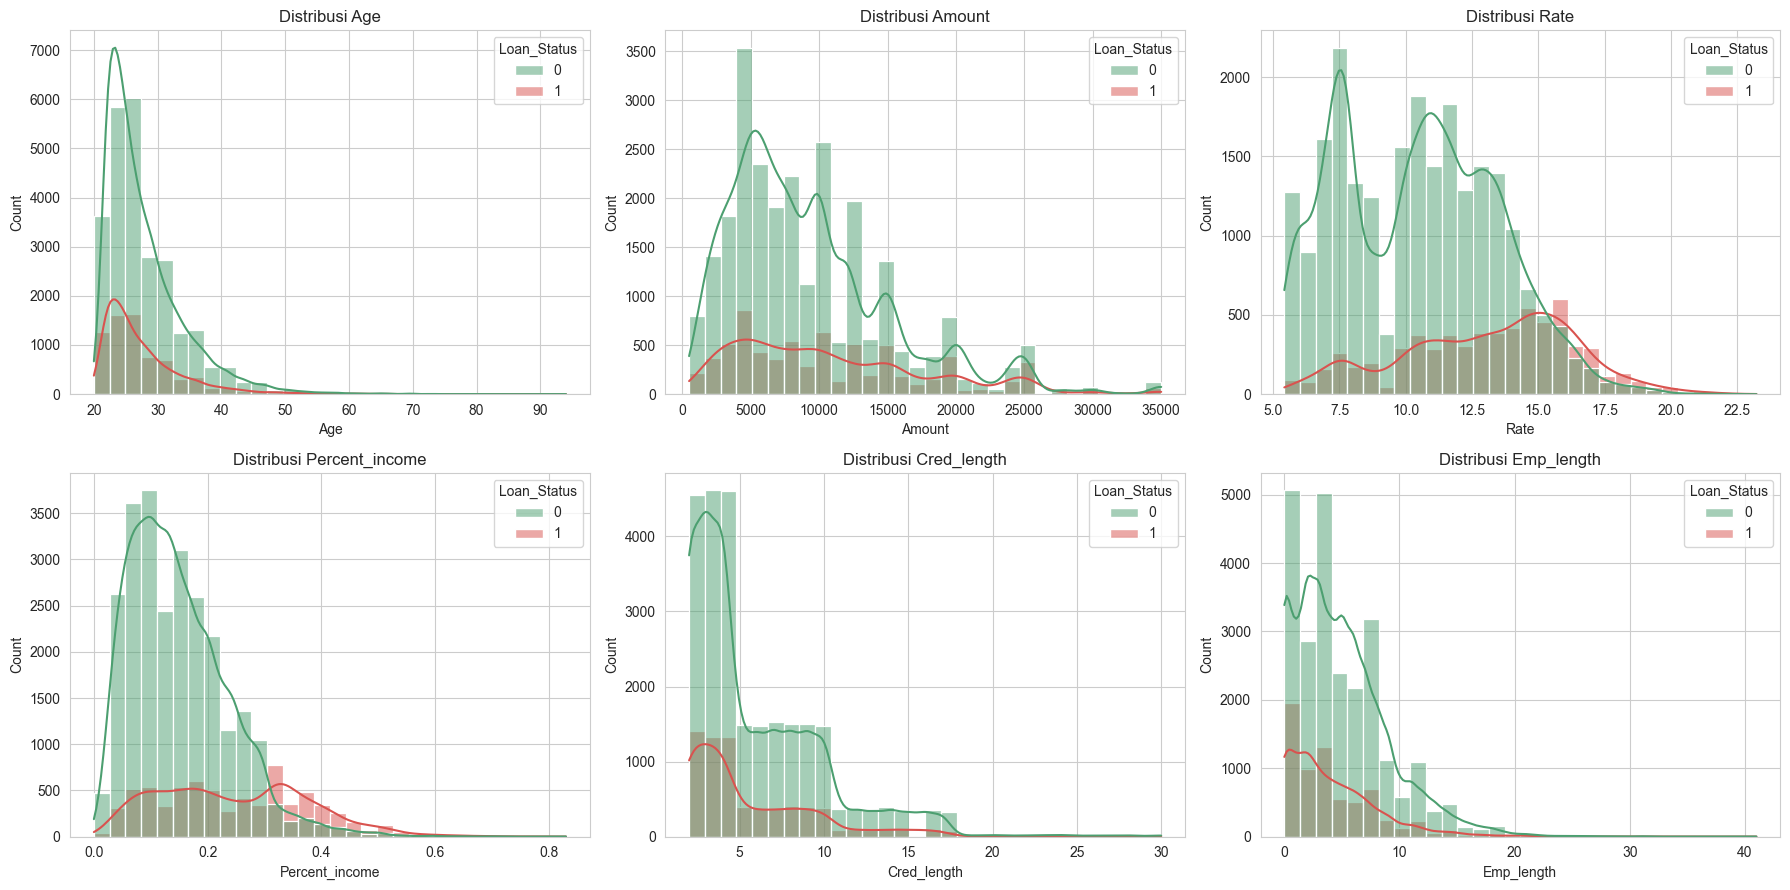

In [10]:
df_plot = df[(df['Age'] <= 100) & (df['Emp_length'].fillna(0) <= 60)]   # hanya untuk visualisasi

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
cols = ['Age', 'Amount', 'Rate', 'Percent_income', 'Cred_length', 'Emp_length']
for ax, col in zip(axes.ravel(), cols):
    sns.histplot(data=df_plot, x=col, hue='Loan_Status', bins=30, kde=True,
                 palette=['#4C9F70', '#D9534F'], ax=ax)
    ax.set_title(f'Distribusi {col}')
plt.tight_layout()
plt.show()

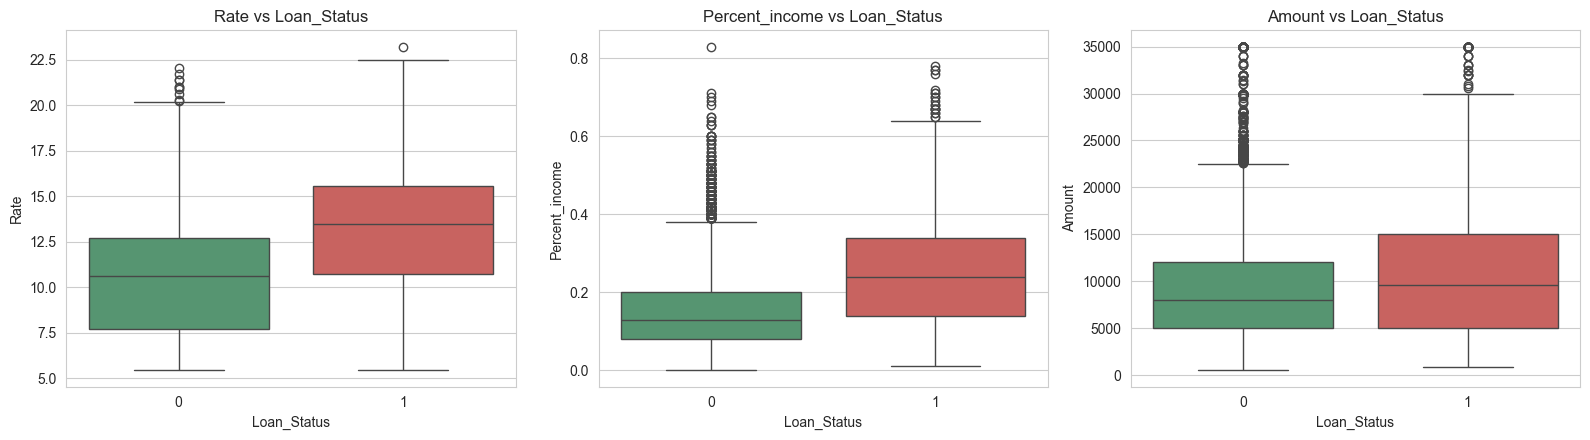

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, col in zip(axes, ['Rate', 'Percent_income', 'Amount']):
    sns.boxplot(x='Loan_Status', y=col, data=df_plot, palette=['#4C9F70', '#D9534F'], ax=ax)
    ax.set_title(f'{col} vs Loan_Status')
plt.tight_layout()
plt.show()

**Insight:** Nasabah yang gagal bayar cenderung memiliki suku bunga (`Rate`) lebih tinggi dan rasio pinjaman terhadap pendapatan (`Percent_income`) lebih besar. Pernah gagal bayar sebelumnya (`Prev_Default = Y`) dan status tempat tinggal sewa (`RENT`) juga berhubungan dengan risiko lebih tinggi.

### 3.5 Korelasi Antar Fitur Numerik

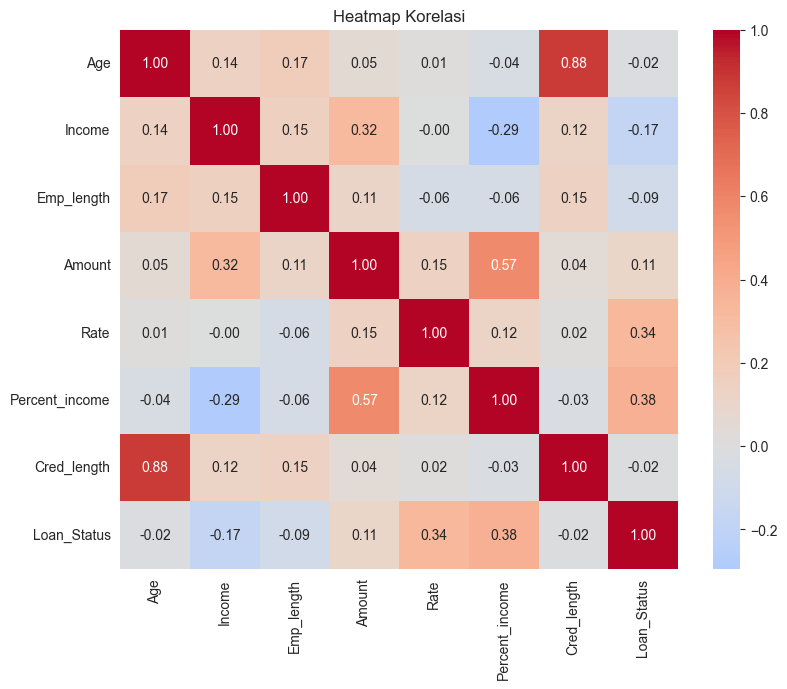

In [12]:
num_eda = ['Age', 'Income', 'Emp_length', 'Amount', 'Rate', 'Percent_income', 'Cred_length', 'Loan_Status']
plt.figure(figsize=(9, 7))
sns.heatmap(df_plot[num_eda].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Heatmap Korelasi')
plt.show()

**Insight:** `Age` dan `Cred_length` berkorelasi tinggi (usia makin tua, riwayat kredit makin panjang). `Percent_income` berkorelasi kuat dengan `Amount`. Pada Regresi Logistik, korelasi antar fitur yang tinggi dapat membuat koefisien kurang stabil, tetapi tidak merusak kemampuan prediksi.

## 4. Pembersihan Data dan Pra-pemrosesan
1. Menghapus kolom `Id` (tidak informatif).
2. Menghapus baris duplikat.
3. Menghapus nilai tidak wajar: `Age > 100` dan `Emp_length > 60`.
4. Mengubah variabel kategorikal menjadi numerik dengan one-hot encoding.

Penanganan missing value (imputasi median) dilakukan **setelah split data** agar tidak terjadi data leakage.

In [13]:
data = df.copy()
n_awal = len(data)

# 1. Hapus kolom Id
data = data.drop(columns=['Id'])

# 2. Hapus duplikat
data = data.drop_duplicates()
print("Setelah hapus duplikat      :", len(data), "baris")

# 3. Hapus nilai tidak wajar (Emp_length yang kosong tetap dipertahankan untuk diimputasi nanti)
data = data[(data['Age'] <= 100) & ((data['Emp_length'] <= 60) | (data['Emp_length'].isnull()))]
print("Setelah hapus outlier       :", len(data), "baris")
print("Total baris dihapus         :", n_awal - len(data))

# 4. One-hot encoding variabel kategorikal (drop_first=True agar tidak terjadi kolinearitas;
#    kategori acuan: Home=MORTGAGE, Intent=DEBTCONSOLIDATION)
data['Prev_Default'] = data['Prev_Default'].map({'N': 0, 'Y': 1})        # biner
data = pd.get_dummies(data, columns=['Home', 'Intent'], drop_first=True, dtype=int)

print("\nUkuran data setelah preprocessing:", data.shape)
print("Missing value tersisa:\n", data.isnull().sum()[data.isnull().sum() > 0])
data.head()

Setelah hapus duplikat      : 32416 baris
Setelah hapus outlier       : 32409 baris
Total baris dihapus         : 172

Ukuran data setelah preprocessing: (32409, 17)
Missing value tersisa:
 Emp_length     887
Rate          3094
dtype: int64


,Age,Income,Emp_length,Amount,Rate,Loan_Status,Percent_income,Prev_Default,Cred_length,Home_OTHER,Home_OWN,Home_RENT,Intent_EDUCATION,Intent_HOMEIMPROVEMENT,Intent_MEDICAL,Intent_PERSONAL,Intent_VENTURE
1,21,9600,5.0,1000,11.14,0,0.10,0,2,0,1,0,1,0,0,0,0
2,25,9600,1.0,5500,12.87,1,0.57,0,3,0,0,0,0,0,1,0,0
3,23,65500,4.0,35000,15.23,1,0.53,0,2,0,0,1,0,0,1,0,0
4,24,54400,8.0,35000,14.27,1,0.55,1,4,0,0,1,0,0,1,0,0
5,21,9900,2.0,2500,7.14,1,0.25,0,2,0,1,0,0,0,0,0,1


## 5. Pembagian Data, Imputasi, Scaling, dan SMOTE

Urutan penting agar **tidak terjadi data leakage**:
1. Split data menjadi data latih dan data uji (stratified).
2. Imputasi missing value (median) dan `StandardScaler`: **di-fit hanya pada data latih**, lalu diterapkan ke data uji.
3. **SMOTE hanya pada data latih.** Data uji dibiarkan asli.

In [14]:
X = data.drop(columns=['Loan_Status'])
y = data['Loan_Status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)
print("Data latih :", X_train.shape)
print("Data uji   :", X_test.shape)

Data latih : (22686, 16)
Data uji   : (9723, 16)


In [15]:
numeric_cols = ['Age', 'Income', 'Emp_length', 'Amount', 'Rate', 'Percent_income', 'Cred_length']

# Imputasi median (di-fit pada data latih)
imputer = SimpleImputer(strategy='median')
X_train = X_train.copy()
X_test = X_test.copy()
X_train[numeric_cols] = imputer.fit_transform(X_train[numeric_cols])
X_test[numeric_cols] = imputer.transform(X_test[numeric_cols])

print("Median hasil imputasi:")
print(dict(zip(numeric_cols, imputer.statistics_.round(2))))
print("\nMissing value di data latih:", X_train.isnull().sum().sum())
print("Missing value di data uji  :", X_test.isnull().sum().sum())

Median hasil imputasi:
{'Age': 26.0, 'Income': 55000.0, 'Emp_length': 4.0, 'Amount': 8000.0, 'Rate': 10.99, 'Percent_income': 0.15, 'Cred_length': 4.0}

Missing value di data latih: 0
Missing value di data uji  : 0


In [16]:
# Scaling fitur numerik (di-fit pada data latih)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])
X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

X_train_scaled.head()

,Age,Income,Emp_length,Amount,Rate,Percent_income,Prev_Default,Cred_length,Home_OTHER,Home_OWN,Home_RENT,Intent_EDUCATION,Intent_HOMEIMPROVEMENT,Intent_MEDICAL,Intent_PERSONAL,Intent_VENTURE
27317,0.695054,1.236218,-0.699962,0.253679,-0.250182,-0.753945,0,-0.194928,0,0,0,0,0,0,0,0
7701,-0.760826,-0.680578,-1.203516,-0.413537,0.540737,0.558718,0,-0.936525,0,0,1,0,0,0,0,1
2586,-0.760826,-0.585687,-0.196408,-1.048980,0.916748,-0.753945,0,-0.689326,0,0,1,0,0,0,1,0
28761,0.371525,-0.225102,-0.699962,-0.731258,1.331656,-0.753945,0,0.299470,0,0,1,0,1,0,0,0
9748,-0.760826,-0.035320,-0.196408,-0.643885,-1.209658,-0.753945,0,-0.442127,0,0,0,0,0,0,0,1


Distribusi kelas SEBELUM SMOTE:
Loan_Status
0    17724
1     4962
Name: count, dtype: int64

Distribusi kelas SESUDAH SMOTE:
Loan_Status
0    17724
1    17724
Name: count, dtype: int64


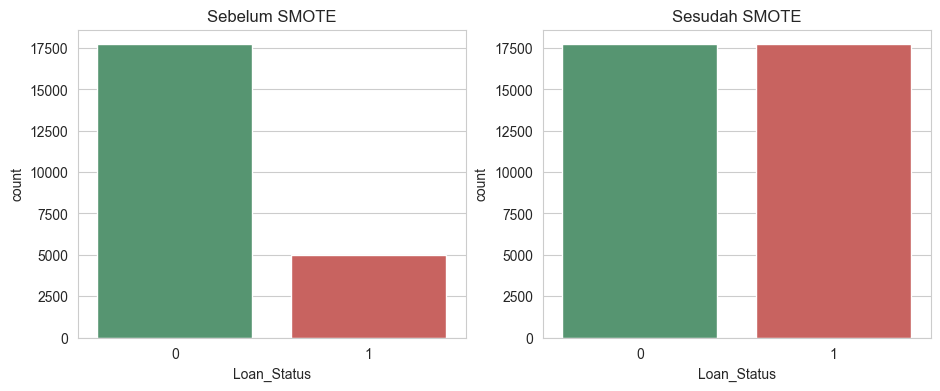

In [17]:
# Menerapkan SMOTE pada data latih
print("Distribusi kelas SEBELUM SMOTE:")
print(y_train.value_counts())

smote = SMOTE(random_state=42)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("\nDistribusi kelas SESUDAH SMOTE:")
print(y_train_res.value_counts())

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.countplot(x=y_train, palette=['#4C9F70', '#D9534F'], ax=axes[0])
axes[0].set_title('Sebelum SMOTE')
sns.countplot(x=y_train_res, palette=['#4C9F70', '#D9534F'], ax=axes[1])
axes[1].set_title('Sesudah SMOTE')
plt.show()

## 6. Pelatihan Model Regresi Logistik

In [18]:
# solver='lbfgs' adalah default dan baik untuk kebanyakan kasus
model = LogisticRegression(solver='lbfgs', max_iter=1000, random_state=42)

# Melatih model menggunakan data latih (hasil SMOTE)
model.fit(X_train_res, y_train_res)
print("Model berhasil dilatih.")

Model berhasil dilatih.


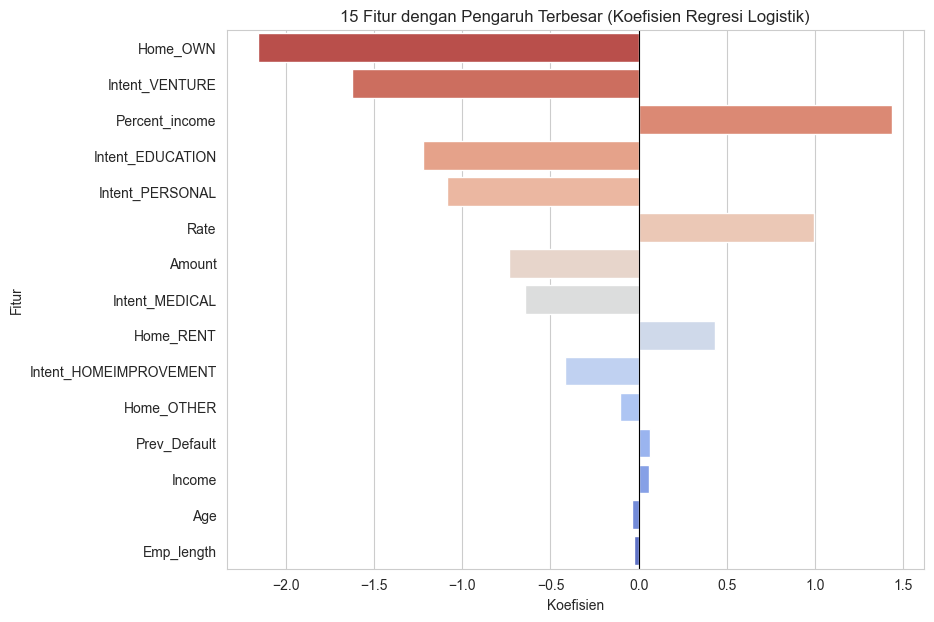

,Fitur,Koefisien
9,Home_OWN,-2.156732
15,Intent_VENTURE,-1.627897
5,Percent_income,1.437682
11,Intent_EDUCATION,-1.221774
14,Intent_PERSONAL,-1.084554
4,Rate,0.996078
3,Amount,-0.735884
13,Intent_MEDICAL,-0.647009
10,Home_RENT,0.434266
12,Intent_HOMEIMPROVEMENT,-0.416063


In [19]:
# Koefisien model: fitur mana yang paling berpengaruh?
coef_df = pd.DataFrame({'Fitur': X.columns, 'Koefisien': model.coef_[0]})
coef_df['Abs'] = coef_df['Koefisien'].abs()
coef_df = coef_df.sort_values('Abs', ascending=False).drop(columns='Abs')

plt.figure(figsize=(9, 7))
sns.barplot(x='Koefisien', y='Fitur', data=coef_df.head(15), palette='coolwarm_r')
plt.axvline(0, color='black', linewidth=0.8)
plt.title('15 Fitur dengan Pengaruh Terbesar (Koefisien Regresi Logistik)')
plt.show()
coef_df.head(10)

**Interpretasi:** Koefisien positif menaikkan peluang gagal bayar, koefisien negatif menurunkannya. Fitur numerik sudah di-scaling sehingga bisa dibandingkan satu sama lain. Untuk fitur kategorikal (hasil one-hot), koefisien dibaca relatif terhadap kategori acuan, yaitu `Home = MORTGAGE` dan `Intent = DEBTCONSOLIDATION`.

## 7. Evaluasi Kinerja Model

In [20]:
# Prediksi pada data uji (threshold default 0.5)
predictions = model.predict(X_test_scaled)

print("--- Classification Report ---")
print(classification_report(y_test, predictions, target_names=['Lancar', 'Gagal Bayar']))

--- Classification Report ---
              precision    recall  f1-score   support

      Lancar       0.92      0.78      0.84      7597
 Gagal Bayar       0.48      0.75      0.59      2126

    accuracy                           0.77      9723
   macro avg       0.70      0.76      0.72      9723
weighted avg       0.82      0.77      0.79      9723



### 7.1 Confusion Matrix

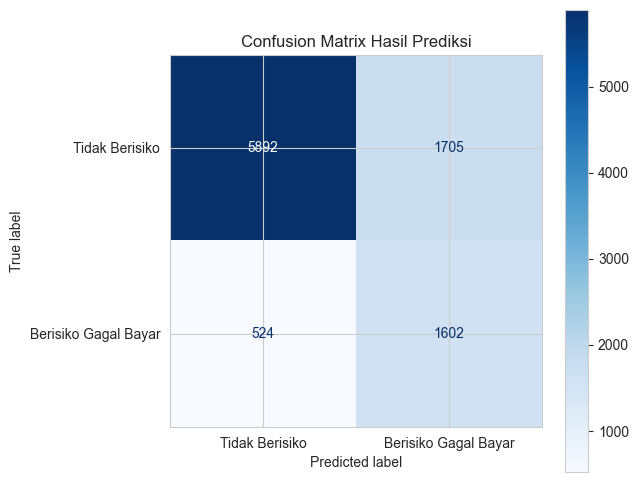

True Negative  (TN): 5892  -> nasabah lancar, diprediksi lancar
False Positive (FP): 1705  -> nasabah lancar, diprediksi BERISIKO
False Negative (FN): 524  -> nasabah gagal bayar, diprediksi AMAN
True Positive  (TP): 1602  -> nasabah gagal bayar, diprediksi berisiko


In [21]:
cm = confusion_matrix(y_test, predictions, labels=model.classes_)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Tidak Berisiko', 'Berisiko Gagal Bayar'])
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(cmap=plt.cm.Blues, ax=ax)
plt.title('Confusion Matrix Hasil Prediksi')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"True Negative  (TN): {tn}  -> nasabah lancar, diprediksi lancar")
print(f"False Positive (FP): {fp}  -> nasabah lancar, diprediksi BERISIKO")
print(f"False Negative (FN): {fn}  -> nasabah gagal bayar, diprediksi AMAN")
print(f"True Positive  (TP): {tp}  -> nasabah gagal bayar, diprediksi berisiko")

### Analisis False Positive vs False Negative

| Jenis Error | Arti | Dampak bagi Perusahaan |
|---|---|---|
| **False Positive (FP)** | Nasabah yang sebenarnya baik diprediksi *berisiko gagal bayar* | Kehilangan peluang bisnis: pengajuan ditolak atau dibatasi, pendapatan bunga dan biaya admin hilang, nasabah bisa pindah ke kompetitor. |
| **False Negative (FN)** | Nasabah yang sebenarnya akan gagal bayar diprediksi *aman* | Kerugian finansial langsung: pokok pinjaman tidak kembali (kredit macet), biaya penagihan, dan pencadangan kerugian (provisi) meningkat. |

**Mana yang lebih merugikan? → False Negative.** Kerugian satu pinjaman macet (pokok yang hilang) umumnya jauh lebih besar daripada pendapatan bunga yang hilang dari satu nasabah baik yang ditolak. Karena itu, model sebaiknya meminimalkan FN, yaitu memaksimalkan **Recall** kelas "Gagal Bayar".

### 7.2 Precision, Recall, F1-Score, dan Accuracy

In [22]:
metrics = pd.DataFrame({
    'Metrik': ['Accuracy', 'Precision (Gagal Bayar)', 'Recall (Gagal Bayar)', 'F1-Score (Gagal Bayar)'],
    'Nilai': [accuracy_score(y_test, predictions),
              precision_score(y_test, predictions),
              recall_score(y_test, predictions),
              f1_score(y_test, predictions)]
})
metrics['Nilai'] = metrics['Nilai'].round(4)
metrics

,Metrik,Nilai
0,Accuracy,0.7707
1,Precision (Gagal Bayar),0.4844
2,Recall (Gagal Bayar),0.7535
3,F1-Score (Gagal Bayar),0.5897


### 7.3 Kurva ROC dan AUC

--- Menghitung AUC dan Membuat Kurva ROC ---
Nilai AUC: 0.8452


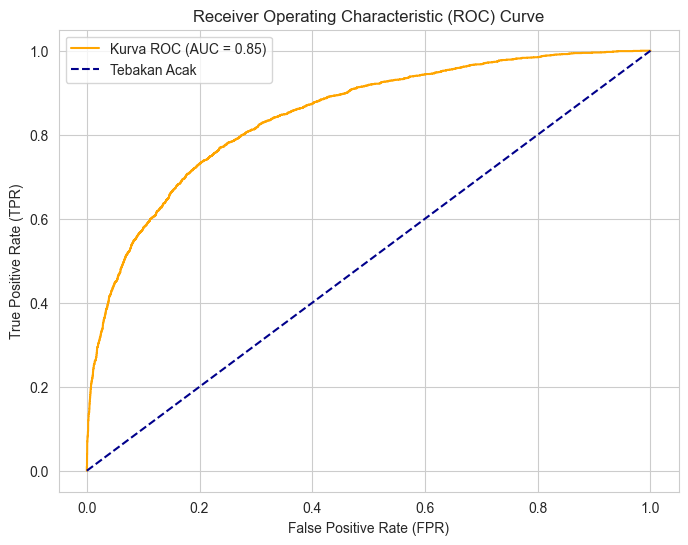

In [23]:
print("--- Menghitung AUC dan Membuat Kurva ROC ---")
# Untuk ROC, kita butuh probabilitas prediksi kelas positif (kelas 1)
y_pred_proba = model.predict_proba(X_test_scaled)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_pred_proba)
auc = roc_auc_score(y_test, y_pred_proba)
print(f"Nilai AUC: {auc:.4f}")

plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='orange', label=f'Kurva ROC (AUC = {auc:.2f})')
plt.plot([0, 1], [0, 1], color='darkblue', linestyle='--', label='Tebakan Acak')
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend()
plt.grid(True)
plt.show()

### Interpretasi Metrik
- **Precision**: dari semua nasabah yang diprediksi *gagal bayar*, berapa persen yang benar-benar gagal bayar. Precision rendah berarti banyak nasabah baik yang salah ditandai (FP tinggi).
- **Recall**: dari semua nasabah yang *benar-benar gagal bayar*, berapa persen yang berhasil terdeteksi. Recall rendah berarti banyak nasabah berisiko lolos (FN tinggi).
- **F1-Score**: rata-rata harmonik Precision dan Recall; berguna untuk data tidak seimbang.
- **AUC**: kemampuan model membedakan kelas di semua threshold (0.5 = acak, 1.0 = sempurna).


## 8. Perbandingan Teknik Penyeimbangan Data
Sebagai pembanding, kita lihat dampak SMOTE dibanding tanpa penyeimbangan dan dibanding `class_weight='balanced'`.

In [24]:
def evaluasi(nama, mdl, Xtr, ytr):
    mdl.fit(Xtr, ytr)
    pred = mdl.predict(X_test_scaled)
    proba = mdl.predict_proba(X_test_scaled)[:, 1]
    return {'Skenario': nama,
            'Accuracy': accuracy_score(y_test, pred),
            'Precision': precision_score(y_test, pred),
            'Recall': recall_score(y_test, pred),
            'F1-Score': f1_score(y_test, pred),
            'AUC': roc_auc_score(y_test, proba)}

hasil = [
    evaluasi('Tanpa penyeimbangan', LogisticRegression(max_iter=1000, random_state=42), X_train_scaled, y_train),
    evaluasi("class_weight='balanced'", LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42), X_train_scaled, y_train),
    evaluasi('SMOTE', LogisticRegression(max_iter=1000, random_state=42), X_train_res, y_train_res),
]
pd.DataFrame(hasil).round(4)

,Skenario,Accuracy,Precision,Recall,F1-Score,AUC
0,Tanpa penyeimbangan,0.8461,0.7269,0.4746,0.5743,0.8475
1,class_weight='balanced',0.7694,0.4829,0.7700,0.5935,0.8480
2,SMOTE,0.7707,0.4844,0.7535,0.5897,0.8452


**Insight:** Tanpa penyeimbangan, model cenderung condong ke kelas mayoritas sehingga Recall kelas "Gagal Bayar" rendah. SMOTE dan `class_weight` sama-sama menaikkan Recall secara signifikan dengan sedikit mengorbankan Precision, sesuai tujuan manajemen risiko.

## 9. (Opsional) Penyesuaian Threshold
Secara default nasabah diprediksi berisiko jika probabilitas ≥ 0.5. Menurunkan threshold menaikkan Recall (FN berkurang) dengan konsekuensi Precision turun (FP bertambah). Pemilihan threshold adalah keputusan bisnis.

In [25]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    pred_t = (y_pred_proba >= t).astype(int)
    rows.append({
        'Threshold': t,
        'Precision': precision_score(y_test, pred_t),
        'Recall': recall_score(y_test, pred_t),
        'F1-Score': f1_score(y_test, pred_t),
        'FN': int(((pred_t == 0) & (y_test == 1)).sum()),
        'FP': int(((pred_t == 1) & (y_test == 0)).sum())
    })
pd.DataFrame(rows).round(4)

,Threshold,Precision,Recall,F1-Score,FN,FP
0,0.3,0.3733,0.8838,0.5249,247,3155
1,0.4,0.4275,0.8264,0.5635,369,2353
2,0.5,0.4844,0.7535,0.5897,524,1705
3,0.6,0.5539,0.6623,0.6033,718,1134
4,0.7,0.6317,0.5640,0.5959,927,699


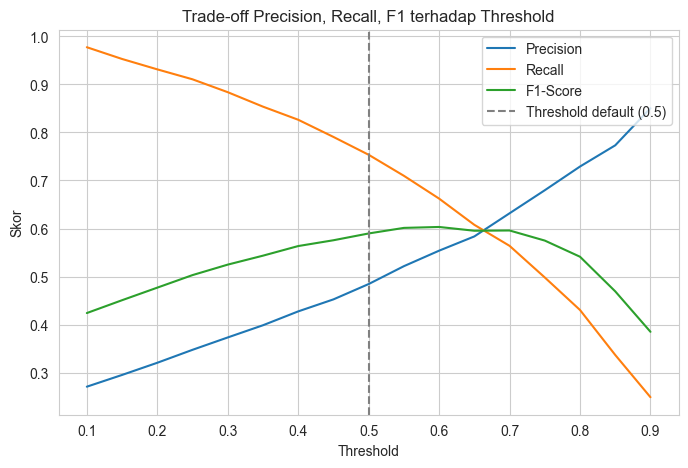

In [26]:
plt.figure(figsize=(8, 5))
ts = np.arange(0.1, 0.91, 0.05)
plt.plot(ts, [precision_score(y_test, (y_pred_proba >= t).astype(int)) for t in ts], label='Precision')
plt.plot(ts, [recall_score(y_test, (y_pred_proba >= t).astype(int)) for t in ts], label='Recall')
plt.plot(ts, [f1_score(y_test, (y_pred_proba >= t).astype(int)) for t in ts], label='F1-Score')
plt.axvline(0.5, color='gray', linestyle='--', label='Threshold default (0.5)')
plt.xlabel('Threshold')
plt.ylabel('Skor')
plt.title('Trade-off Precision, Recall, F1 terhadap Threshold')
plt.legend()
plt.grid(True)
plt.show()

## 10. Menyimpan Model dan Scaler (Joblib)
File disimpan ke folder `model/`:
- `logistic_regression_model.joblib` : model terlatih
- `scaler.joblib` : objek `StandardScaler`
- `imputer.joblib` : objek `SimpleImputer` (untuk mengisi nilai kosong, jika ada)
- `feature_columns.joblib` : urutan kolom fitur (**wajib sama persis** saat prediksi di Flask)
- `numeric_cols.joblib` : daftar kolom yang di-scaling

In [27]:
# Membuat folder model jika belum ada
os.makedirs('../model', exist_ok=True)

joblib.dump(model, '../model/logistic_regression_model.joblib')
joblib.dump(scaler, '../model/scaler.joblib')
joblib.dump(imputer, '../model/imputer.joblib')
joblib.dump(list(X.columns), '../model/feature_columns.joblib')
joblib.dump(numeric_cols, '../model/numeric_cols.joblib')

print("File di folder 'model':")
for f in sorted(os.listdir('../model')):
    print(" -", f)

File di folder 'model':
 - feature_columns.joblib
 - imputer.joblib
 - logistic_regression_model.joblib
 - numeric_cols.joblib
 - scaler.joblib


## 11. Uji Coba Pemuatan Model dan Prediksi Satu Nasabah
Bagian ini mensimulasikan apa yang akan dilakukan aplikasi Flask: memuat model dan scaler, lalu memprediksi data nasabah baru. Fungsi di bawah dapat langsung disalin ke Flask.

**Input form yang dibutuhkan (9 field):** `Age`, `Income`, `Home`, `Emp_length`, `Intent`, `Amount`, `Rate`, `Cred_length`, `Prev_Default`.
`Percent_income` **dihitung otomatis** dari `Amount / Income`, sehingga tidak perlu diisi analis.

Pilihan nilai untuk form: `Home` ∈ {RENT, OWN, MORTGAGE, OTHER}; `Intent` ∈ {PERSONAL, EDUCATION, MEDICAL, VENTURE, HOMEIMPROVEMENT, DEBTCONSOLIDATION}; `Prev_Default` ∈ {Y, N}.

In [29]:
# Memuat kembali model dan objek pendukung
loaded_model = joblib.load('../model/logistic_regression_model.joblib')
loaded_scaler = joblib.load('../model/scaler.joblib')
loaded_imputer = joblib.load('../model/imputer.joblib')
feature_columns = joblib.load('../model/feature_columns.joblib')
num_cols = joblib.load('../model/numeric_cols.joblib')

def prediksi_nasabah(input_dict, threshold=0.5):
    """
    input_dict berisi nilai mentah (belum di-scale), contoh:
    {'Age': 25, 'Income': 40000, 'Home': 'RENT', 'Emp_length': 3, 'Intent': 'PERSONAL',
     'Amount': 10000, 'Rate': 13.5, 'Cred_length': 3, 'Prev_Default': 'N'}
    """
    row = pd.DataFrame([input_dict])

    # Percent_income dihitung otomatis
    row['Percent_income'] = (row['Amount'] / row['Income']).round(2)

    # Encoding sama persis seperti saat training
    row['Prev_Default'] = row['Prev_Default'].map({'N': 0, 'Y': 1})
    row = pd.get_dummies(row, columns=['Home', 'Intent'], drop_first=True, dtype=int)

    # Menyamakan kolom dengan data training (kategori yang tidak ada diisi 0)
    row = row.reindex(columns=feature_columns, fill_value=0)

    # Imputasi, scaling, lalu prediksi
    row[num_cols] = loaded_imputer.transform(row[num_cols])
    row[num_cols] = loaded_scaler.transform(row[num_cols])
    proba = loaded_model.predict_proba(row)[0, 1]
    label = 'Berisiko Gagal Bayar' if proba >= threshold else 'Tidak Berisiko'
    return label, proba

# Contoh 1: nasabah dengan profil berisiko
contoh_berisiko = {
    'Age': 22, 'Income': 20000, 'Home': 'RENT', 'Emp_length': 1, 'Intent': 'MEDICAL',
    'Amount': 12000, 'Rate': 19.5, 'Cred_length': 2, 'Prev_Default': 'Y'
}
label, proba = prediksi_nasabah(contoh_berisiko)
print("Contoh 1 (profil berisiko)")
print(f"  Hasil Prediksi : {label}")
print(f"  Probabilitas   : {proba:.2%}")

Contoh 1 (profil berisiko)
  Hasil Prediksi : Berisiko Gagal Bayar
  Probabilitas   : 99.98%


In [30]:
# Contoh 2: nasabah dengan profil aman
contoh_aman = {
    'Age': 40, 'Income': 120000, 'Home': 'MORTGAGE', 'Emp_length': 12, 'Intent': 'HOMEIMPROVEMENT',
    'Amount': 8000, 'Rate': 7.5, 'Cred_length': 14, 'Prev_Default': 'N'
}
label, proba = prediksi_nasabah(contoh_aman)
print("Contoh 2 (profil aman)")
print(f"  Hasil Prediksi : {label}")
print(f"  Probabilitas   : {proba:.2%}")

Contoh 2 (profil aman)
  Hasil Prediksi : Tidak Berisiko
  Probabilitas   : 9.81%


## 12. Kesimpulan
- Dataset Credit Risk memiliki ketidakseimbangan kelas (~22% gagal bayar), sehingga SMOTE diterapkan **hanya pada data latih**.
- Pembersihan data mencakup penghapusan duplikat, nilai tidak wajar (usia dan lama kerja), serta imputasi median untuk missing value.
- Imputer dan scaler di-*fit* hanya pada data latih untuk mencegah data leakage.
- Faktor yang paling memengaruhi risiko gagal bayar: status kepemilikan rumah, tujuan pinjaman, rasio pinjaman terhadap pendapatan, dan suku bunga.
- Metrik utama adalah **Recall kelas Gagal Bayar**, didukung F1-Score dan AUC, karena False Negative paling merugikan perusahaan.
- Model, scaler, imputer, urutan kolom fitur, dan daftar kolom numerik telah disimpan di folder `model/` dan siap diintegrasikan ke aplikasi Flask.